# 03 · Model Tournament, Tuning & Calibration
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/KrishKamra/Customer_Churn_Prediction/blob/main/notebooks/03_model_benchmarking_tuning.ipynb)

Six contenders, one shared leakage-free pipeline, Repeated Stratified 5-Fold CV, isotonic
calibration and a cost-optimal decision threshold (`Cost = 5·FN + 1·FP`).

| Contender | Family |
| :--- | :--- |
| ElasticNet Logistic Regression (`class_weight="balanced"`) | linear baseline |
| Balanced Random Forest (imbalanced-learn) | bagging |
| LightGBM · XGBoost · CatBoost | gradient boosting |
| Stacking (CatBoost + XGBoost + LR → logistic meta-learner) | ensemble |

### 🚀 Runtime: **GPU → L4, High-RAM** (pre-selected in this notebook's metadata)
`Runtime ▸ Change runtime type` should already show *L4 GPU* + *High-RAM*. On a GPU the
notebook trains XGBoost (`device="cuda"`) and CatBoost (`task_type="GPU"`) on the GPU and
enables hyper-parameter search (`TUNE_ITER`). Why L4 rather than A100/H100: the dataset is
7k rows, so the bigger cards finish no faster but burn several times more Colab compute
units. With no GPU attached everything still runs on CPU, just slower.

Artifacts written: `models/production_pipeline.joblib`, `models/model_metadata.json`,
`docs/benchmarks.md`, `docs/evaluations/model_benchmarks.json`, `docs/figures/*.png`.

### 🔑 One-time setup for auto-push
1. On GitHub, create a fine-grained token: **Settings ▸ Developer settings ▸ Fine-grained tokens**,
   limited to this repository, with **Contents: Read and write**.
2. In Colab, open the **🔑 Secrets** sidebar, add `GITHUB_TOKEN` and switch on **Notebook access**.

After that, **Runtime ▸ Run all** trains, validates and pushes the results back to GitHub.

In [1]:
# ⚙️ Environment bootstrap — identical on Google Colab and locally.
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/KrishKamra/Customer_Churn_Prediction.git"

if IN_COLAB:
    ROOT = Path("/content/Customer_Churn_Prediction")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    os.chdir(ROOT)
    # uv resolves in seconds and keeps Colab's preinstalled, compatible wheels.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "uv"], check=True)
    subprocess.run(["uv", "pip", "install", "--system", "-q", "-e", ".[notebooks]"], check=True)
else:
    ROOT = Path.cwd().resolve()
    while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    os.chdir(ROOT)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT} | Colab: {IN_COLAB}")

Project root: C:\Users\krish\workspace\archive\Customer_Churn_Prediction | Colab: False


## 0 · Hardware & run configuration

In [2]:
import json
import time
import warnings

from src.core.hardware import gpu_name, resolve_device

DEVICE = resolve_device("auto")
if DEVICE == "cuda":
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
print(f"Device: {DEVICE} ({gpu_name() or 'no GPU'}) · CPU cores: {os.cpu_count()}")

# Retrain from scratch (default). Set CHURNAI_NB_RETRAIN=0 to reuse committed artifacts.
RETRAIN = os.getenv("CHURNAI_NB_RETRAIN", "1") == "1"
# Hyper-parameter search iterations for the champion: on by default on GPU.
TUNE_ITER = int(os.getenv("CHURNAI_TUNE_ITER", "30" if DEVICE == "cuda" else "0"))
CV_REPEATS = int(os.getenv("CHURNAI_CV_REPEATS", "3" if DEVICE == "cuda" else "2"))
print(f"RETRAIN={RETRAIN} · TUNE_ITER={TUNE_ITER} · CV_REPEATS={CV_REPEATS}")

Device: cpu (no GPU) · CPU cores: 16
RETRAIN=True · TUNE_ITER=0 · CV_REPEATS=2


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import shap
from sklearn.calibration import calibration_curve

from src.analytics.plotting import PALETTE, apply_theme, save
from src.config import get_settings
from src.features.engineer import clean_raw, load_raw, split_features_target
from src.models.evaluate import compute_metrics, holdout_split, validate_thresholds
from src.models.explainability import PRETTY_NAMES, ChurnExplainer, generate_counterfactuals
from src.models.inference import ChurnPredictor
from src.models.train import run_tournament

warnings.filterwarnings("ignore", message=".*feature names.*")
apply_theme()
settings = get_settings().model_copy(update={"cv_repeats": CV_REPEATS})
FIG = settings.figures_dir

C:\Users\krish\workspace\archive\Customer_Churn_Prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1 · Leakage-free split

In [4]:
df = clean_raw(load_raw())
train_df, test_df = holdout_split(df, settings)
X_train, y_train = split_features_target(train_df)
X_test, y_test = split_features_target(test_df)
print(
    f"train {len(train_df):,} ({y_train.mean():.2%} churn) · "
    f"holdout {len(test_df):,} ({y_test.mean():.2%} churn)"
)

train 5,634 (26.54% churn) · holdout 1,409 (26.54% churn)


The holdout is carved off **once** with a fixed seed and is never used for model selection,
tuning, calibration or threshold choice — only for the final report and the CI gate (which
verifies its SHA-256 fingerprint). Inside CV, every fold re-fits imputation, scaling, one-hot
vocabularies, target-derived risk ratios **and** calibration on the training fold only.

## 2 · Run the tournament

In [5]:
if RETRAIN:
    t0 = time.perf_counter()
    result = run_tournament(settings, tune_iter=TUNE_ITER, device=DEVICE)
    print(
        f"⏱️ tournament finished in {(time.perf_counter() - t0) / 60:.1f} min · "
        f"champion = {result.champion}"
    )
bench = json.loads((settings.evaluations_dir / "model_benchmarks.json").read_text())
meta = json.loads(settings.metadata_path.read_text())
print("champion:", meta["champion_display_name"], "| threshold:", meta["decision_threshold"])

21:33:09 | INFO    | churnai.train | Starting tournament | device=cpu gpu=None models=elasticnet_lr,balanced_rf,lightgbm,xgboost,catboost,stacking folds=5 repeats=2


21:33:16 | INFO    | churnai.train | CV ElasticNet Logistic Regression | pr_auc=0.6549 roc_auc=0.8492 brier=0.1332 secs=6.9


21:33:26 | INFO    | churnai.train | CV Balanced Random Forest | pr_auc=0.6371 roc_auc=0.8436 brier=0.1364 secs=10.1


21:33:28 | INFO    | churnai.train | CV LightGBM | pr_auc=0.6359 roc_auc=0.8426 brier=0.1365 secs=2.3


21:33:32 | INFO    | churnai.train | CV XGBoost | pr_auc=0.6487 roc_auc=0.8463 brier=0.1347 secs=3.6


21:33:45 | INFO    | churnai.train | CV CatBoost | pr_auc=0.6364 roc_auc=0.8418 brier=0.1368 secs=13.6


21:35:44 | INFO    | churnai.train | CV Stacking (CatBoost + XGBoost + LR) | pr_auc=0.6524 roc_auc=0.8491 brier=0.1332 secs=118.8


21:35:44 | INFO    | churnai.train | Champion selected | champion=elasticnet_lr


21:38:45 | INFO    | churnai.train | Artifacts written | model=C:\Users\krish\workspace\archive\Customer_Churn_Prediction\models\production_pipeline.joblib


⏱️ tournament finished in 5.6 min · champion = elasticnet_lr
champion: ElasticNet Logistic Regression | threshold: 0.185


## 3 · Leaderboard

In [6]:
rows = []
for key, r in bench["models"].items():
    rows.append(
        {
            "model": r["display_name"],
            "cv_pr_auc": r["cv_mean"]["pr_auc"],
            "cv_pr_auc_std": r["cv_std"]["pr_auc"],
            "cv_roc_auc": r["cv_mean"]["roc_auc"],
            "cv_brier": r["cv_mean"]["brier"],
            "threshold": r["oof_threshold"],
            "holdout_roc_auc": r["holdout"]["roc_auc"],
            "holdout_pr_auc": r["holdout"]["pr_auc"],
            "holdout_recall": r["holdout"]["recall"],
            "holdout_precision": r["holdout"]["precision"],
            "holdout_f2": r["holdout"]["f2"],
            "expected_loss_usd": r["holdout"]["expected_loss_usd"],
            "fit_s": r["fit_time_s"],
            "latency_ms": r["latency_ms"],
        }
    )
board = pd.DataFrame(rows).sort_values("cv_pr_auc", ascending=False).reset_index(drop=True)
board.style.format(precision=3).format({"expected_loss_usd": "${:,.0f}"}).background_gradient(
    subset=["cv_pr_auc", "holdout_pr_auc"], cmap="Purples"
)

,model,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,cv_brier,threshold,holdout_roc_auc,holdout_pr_auc,holdout_recall,holdout_precision,holdout_f2,expected_loss_usd,fit_s,latency_ms
0,ElasticNet Logistic Regression,0.654928,0.018429,0.849187,0.133196,0.185000,0.848090,0.650613,0.860963,0.477037,0.741594,"$30,650",4.183065,14.037950
1,Stacking (CatBoost + XGBoost + LR),0.652353,0.018458,0.849051,0.133207,0.175000,0.848568,0.646813,0.866310,0.468886,0.740741,"$30,850",116.529563,18.754800
2,XGBoost,0.648679,0.017599,0.846293,0.134737,0.185000,0.843176,0.637089,0.906417,0.447820,0.752330,"$29,650",3.209172,14.492800
3,Balanced Random Forest,0.637074,0.023633,0.843571,0.136433,0.155000,0.840615,0.631945,0.890374,0.456790,0.748315,"$30,050",7.541000,25.752350
4,CatBoost,0.636433,0.018145,0.841817,0.136843,0.165000,0.841532,0.643013,0.919786,0.418491,0.742019,"$31,400",13.210830,13.725100
5,LightGBM,0.635852,0.021702,0.842625,0.136535,0.205000,0.838302,0.630585,0.874332,0.463173,0.742507,"$30,700",1.974767,13.328750


In [7]:
fig = go.Figure(
    go.Bar(
        x=board["model"],
        y=board["cv_pr_auc"],
        error_y={"type": "data", "array": board["cv_pr_auc_std"]},
        marker_color=[
            PALETTE["emerald"] if m == meta["champion_display_name"] else PALETTE["violet"]
            for m in board["model"]
        ],
    )
)
fig.update_layout(
    template="plotly_dark",
    paper_bgcolor=PALETTE["bg"],
    plot_bgcolor=PALETTE["panel"],
    title="Cross-validated PR-AUC (± 1 SD)",
    yaxis_range=[0.55, 0.72],
    height=420,
)
fig.show()

Differences among the top contenders sit inside one CV standard deviation — expected on a
dataset whose non-leaky ceiling is ROC-AUC ≈ 0.84–0.86. Calibration and the cost-aware
threshold matter more for business value than the choice of algorithm.

## 4 · ROC / PR curves (holdout)

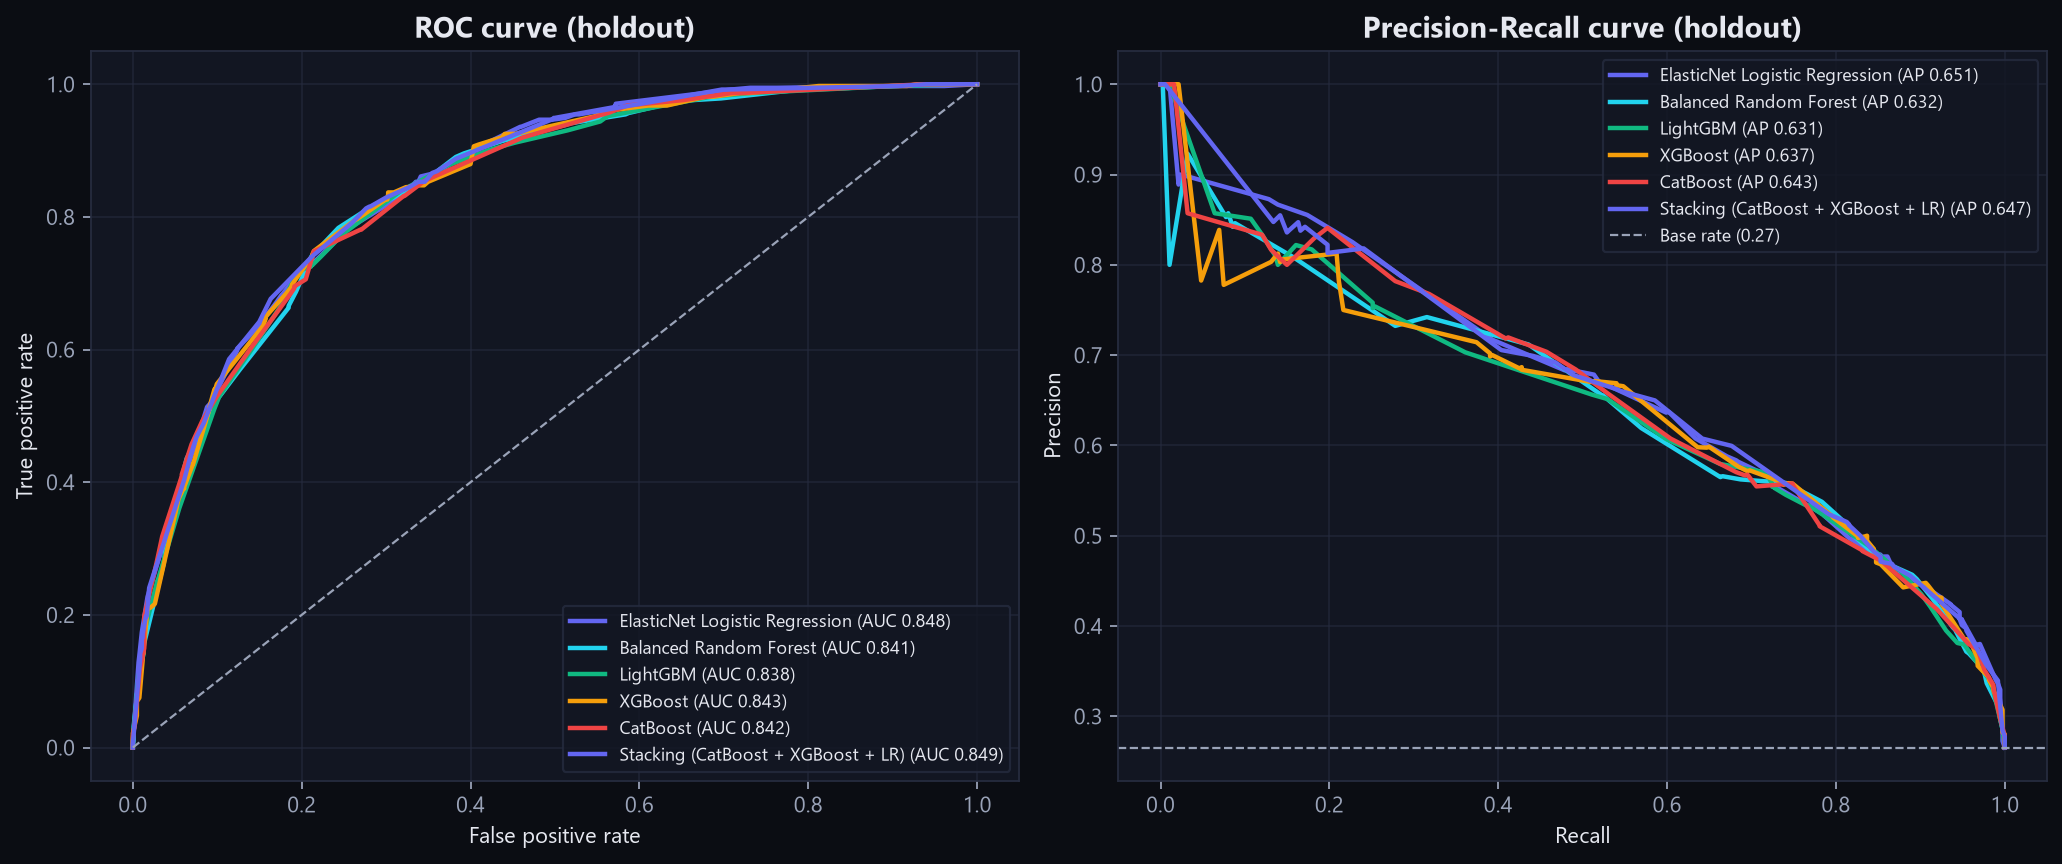

In [8]:
from IPython.display import Image

Image(filename=str(FIG / "roc_pr_curves.png"))

## 5 · Calibration & cost-optimal threshold (champion)

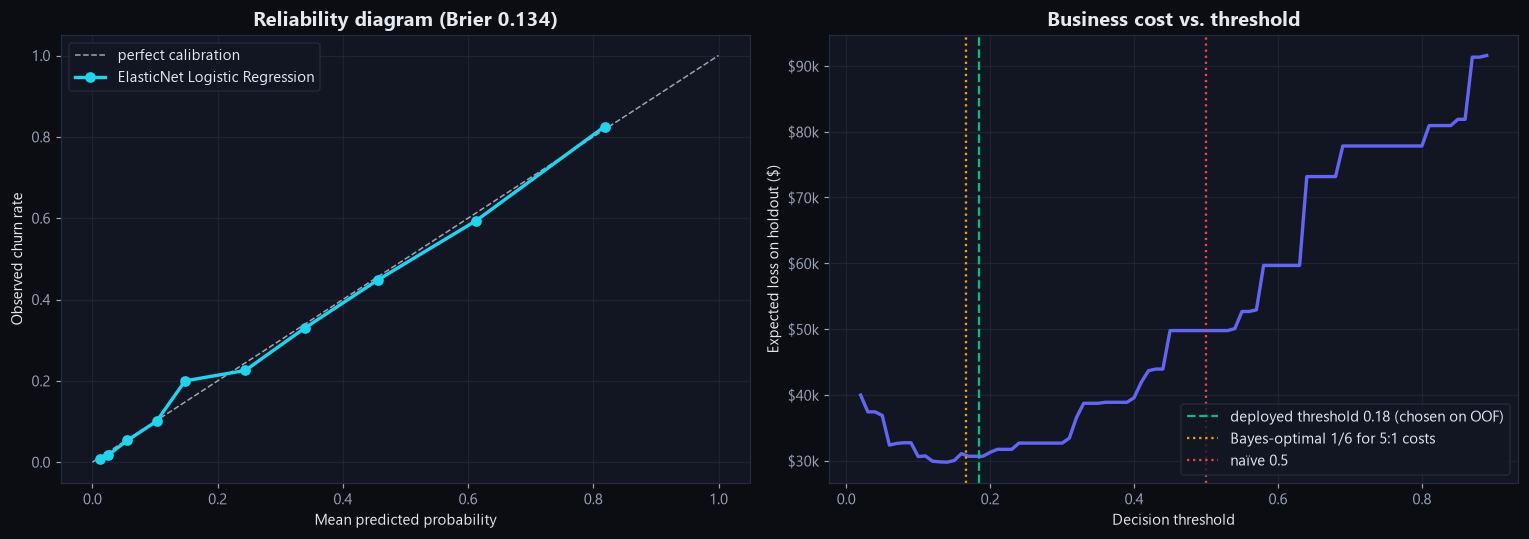

In [9]:
predictor = ChurnPredictor.load()
proba = predictor.predict_proba(X_test)
frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10, strategy="quantile")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot([0, 1], [0, 1], ls="--", c=PALETTE["muted"], lw=1, label="perfect calibration")
ax1.plot(mean_pred, frac_pos, marker="o", lw=2.2, c=PALETTE["cyan"], label=predictor.champion_name)
ax1.set(
    xlabel="Mean predicted probability",
    ylabel="Observed churn rate",
    title=f"Reliability diagram (Brier {compute_metrics(y_test, proba)['brier']:.3f})",
)
ax1.legend()

grid = np.round(np.arange(0.02, 0.9, 0.01), 2)
costs = [compute_metrics(y_test, proba, t, settings)["expected_loss_usd"] for t in grid]
ax2.plot(grid, costs, lw=2.2, c=PALETTE["violet"])
ax2.axvline(
    predictor.threshold,
    c=PALETTE["emerald"],
    ls="--",
    label=f"deployed threshold {predictor.threshold:.2f} (chosen on OOF)",
)
ax2.axvline(1 / 6, c=PALETTE["amber"], ls=":", label="Bayes-optimal 1/6 for 5:1 costs")
ax2.axvline(0.5, c=PALETTE["crimson"], ls=":", label="naïve 0.5")
ax2.set(
    xlabel="Decision threshold",
    ylabel="Expected loss on holdout ($)",
    title="Business cost vs. threshold",
)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k"))
ax2.legend()
fig.tight_layout()
save(fig, FIG / "calibration_and_cost.png");

In [10]:
at_05 = compute_metrics(y_test, proba, 0.5, settings)
at_opt = compute_metrics(y_test, proba, predictor.threshold, settings)
pd.DataFrame({"threshold 0.50": at_05, f"threshold {predictor.threshold:.2f}": at_opt}).loc[
    ["recall", "precision", "f2", "tp", "fp", "fn", "expected_loss_usd"]
]

,threshold 0.50,threshold 0.18
recall,0.518717,0.860963
precision,0.671280,0.477037
f2,0.543417,0.741594
tp,194.000000,322.000000
fp,95.000000,353.000000
fn,180.000000,52.000000
expected_loss_usd,49750.000000,30650.000000


## 6 · Global explainability (SHAP)

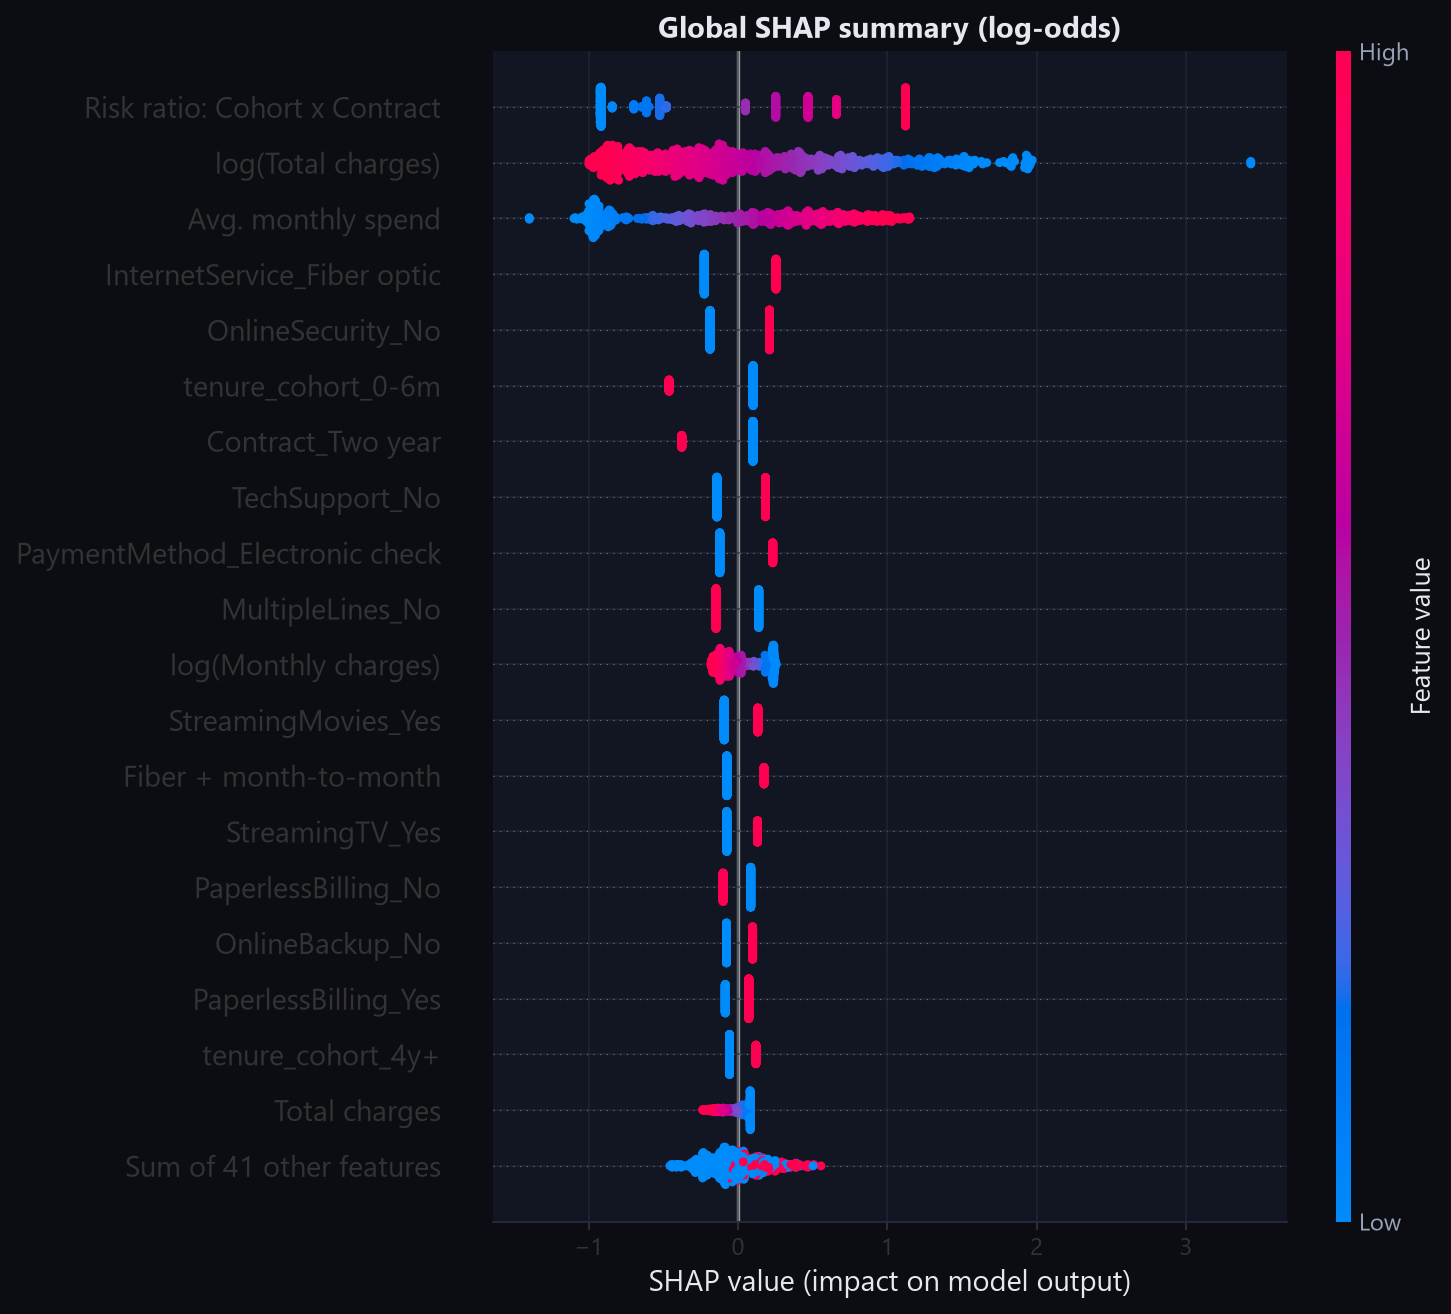

In [11]:
Image(filename=str(FIG / "shap_summary.png"))

,feature,mean_abs_shap
0,risk_ratio__tenure_cohort_x_Contract,0.702
1,log_total_charges,0.605
2,avg_monthly_spend,0.579
3,tenure_cohort,0.321
4,InternetService,0.238
5,Contract,0.230
6,OnlineSecurity,0.199
7,PaperlessBilling,0.168
8,PaymentMethod,0.165
9,TechSupport,0.163


<Figure size 880x550 with 0 Axes>

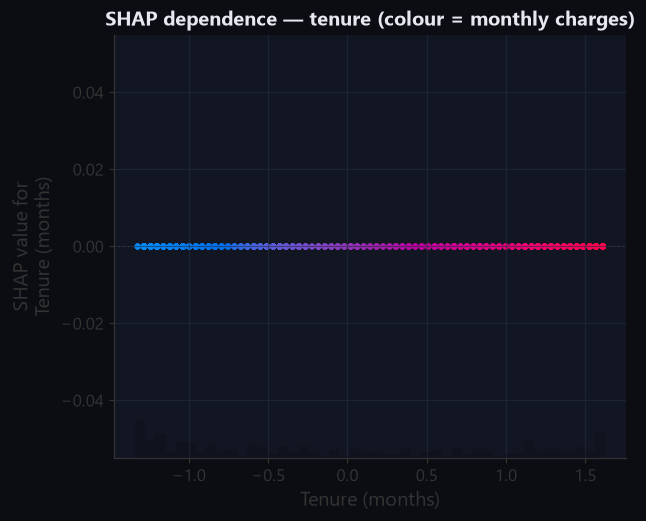

In [12]:
explainer = ChurnExplainer(predictor.model, X_train)
importance = explainer.global_importance(X_test.head(400))
display(
    importance.head(12)
    .style.format({"mean_abs_shap": "{:.3f}"})
    .bar(subset=["mean_abs_shap"], color=PALETTE["violet"])
)

exp = explainer.shap_values(X_test.head(800))
if "tenure" in exp.feature_names:
    exp.feature_names = [PRETTY_NAMES.get(n, n) for n in exp.feature_names]
    plt.figure(figsize=(8, 5))
    shap.plots.scatter(
        exp[:, PRETTY_NAMES["tenure"]], color=exp[:, PRETTY_NAMES["MonthlyCharges"]], show=False
    )
    plt.title("SHAP dependence — tenure (colour = monthly charges)")
    save(plt.gcf(), FIG / "shap_dependence_tenure.png")
    plt.show()

## 7 · Local explanation & counterfactual prescriptions

In [13]:
idx = int(np.argmax(proba))
customer = X_test.iloc[[idx]]
local = explainer.explain_instance(customer)
print(
    f"Customer {test_df.iloc[idx]['customerID']}: p(churn) = {proba[idx]:.1%} "
    f"(actual: {'churned' if y_test.iloc[idx] else 'retained'})"
)
display(local.top(8)[["label", "shap"]].style.format({"shap": "{:+.3f}"}))
for cf in generate_counterfactuals(predictor.predict_proba, customer, top_k=5):
    print(" •", cf.description)

Customer 5178-LMXOP: p(churn) = 100.0% (actual: churned)


,label,shap
4,log(Total charges) = 4.57,+1.196
13,Risk ratio: Cohort x Contract = 2.03,+1.122
7,Avg. monthly spend = 95.10,+0.664
29,Tenure cohort = 0-6m,-0.533
19,InternetService = Fiber optic,+0.254
28,PaymentMethod = Electronic check,+0.238
20,OnlineSecurity = No,+0.211
23,TechSupport = No,+0.184


 • Migrate to a two-year contract reduces churn risk from 100% to 57%
 • Retention bundle (annual + auto-pay + support) reduces churn risk from 100% to 64%
 • Migrate to a one-year contract reduces churn risk from 100% to 69%
 • Switch to automatic credit-card payment reduces churn risk from 100% to 95%
 • Bundle Tech Support reduces churn risk from 100% to 95%


## 8 · Model validation gate (same check CI runs)

In [14]:
gate = validate_thresholds(settings)
print("✅ gate passed:", {k: round(gate[k], 4) for k in ("roc_auc", "pr_auc", "recall", "brier")})

21:38:47 | INFO    | churnai.evaluate | gate roc_auc | value=0.8481 bound=>=0.82


21:38:47 | INFO    | churnai.evaluate | gate pr_auc | value=0.6506 bound=>=0.6


21:38:47 | INFO    | churnai.evaluate | gate recall | value=0.861 bound=>=0.75


21:38:47 | INFO    | churnai.evaluate | gate brier | value=0.1343 bound=<=0.16


✅ gate passed: {'roc_auc': 0.8481, 'pr_auc': 0.6506, 'recall': 0.861, 'brier': 0.1343}


## 9 · Publish results to GitHub

On Colab this cell commits `models/`, `docs/` and `data/processed/` and pushes them to a new
`colab/retrain-<timestamp>` branch, then prints a pull-request link. CI re-runs the model gate
on that PR before anything reaches `main`. Set `PUSH_BRANCH = "main"` to skip the PR. Without
a `GITHUB_TOKEN` secret it falls back to downloading a zip.

In [15]:
# 🚀 Colab only: commit the retrained artifacts straight back to GitHub.
# One-time setup: Colab sidebar 🔑 Secrets → add GITHUB_TOKEN (fine-grained PAT,
# "Contents: Read and write" on this repo) and switch on "Notebook access".
AUTO_PUSH = True
PUSH_BRANCH = None  # None → new branch "colab/retrain-<UTC stamp>" (open a PR); or "main"
GIT_NAME, GIT_EMAIL = "ChurnAI Colab", "churnai-colab@users.noreply.github.com"
ARTIFACT_PATHS = ["models", "docs", "data/processed"]


def _git(*args: str, secret: str = "") -> str:
    out = subprocess.run(["git", *args], capture_output=True, text=True)
    text = out.stdout + out.stderr
    if secret:
        text = text.replace(secret, "***")  # never echo the token
    if out.returncode != 0:
        raise RuntimeError(f"git {args[0]} failed: {text.strip()}")
    return text


def push_artifacts() -> bool:
    from datetime import UTC, datetime

    from google.colab import userdata

    try:
        token = userdata.get("GITHUB_TOKEN")
    except Exception as exc:  # SecretNotFoundError / NotebookAccessError
        print(f"⚠️ GITHUB_TOKEN secret unavailable ({type(exc).__name__}).")
        return False
    if not _git("status", "--porcelain", "--", *ARTIFACT_PATHS).strip():
        print("ℹ️ Artifacts are identical to the repo — nothing to push.")
        return True

    meta = json.loads(settings.metadata_path.read_text())
    h = meta["holdout"]
    branch = PUSH_BRANCH or f"colab/retrain-{datetime.now(UTC):%Y%m%d-%H%M}"
    message = (
        f"feat(models): retrain {meta['champion_display_name']} on Colab "
        f"({meta.get('gpu') or meta['device']})\n\n"
        f"- holdout PR-AUC {h['pr_auc']:.4f}, ROC-AUC {h['roc_auc']:.4f}, "
        f"recall {h['recall']:.3f}, Brier {h['brier']:.4f}\n"
        f"- decision threshold {meta['decision_threshold']:.3f}, "
        f"tune_iter {TUNE_ITER}, cv_repeats {CV_REPEATS}\n"
        f"- model_version {meta['model_version']}\n"
    )
    repo = REPO_URL.removeprefix("https://")
    _git("config", "user.name", GIT_NAME)
    _git("config", "user.email", GIT_EMAIL)
    _git("checkout", "-B", branch)
    _git("add", "--", *ARTIFACT_PATHS)
    _git("commit", "-m", message)
    _git(
        "push",
        f"https://x-access-token:{token}@{repo}",
        f"HEAD:refs/heads/{branch}",
        secret=token,
    )
    web = "https://" + repo.removesuffix(".git")
    print(f"✅ Pushed to '{branch}'.")
    if branch != "main":
        print(f"👉 Open a PR (CI re-runs the model gate): {web}/compare/{branch}?expand=1")
    return True


if IN_COLAB:
    pushed = False
    if AUTO_PUSH:
        try:
            pushed = push_artifacts()
        except RuntimeError as exc:
            print(f"⚠️ {exc}")
    if not pushed:
        import shutil

        from google.colab import files

        print("Falling back to a zip download — unzip over your clone and commit.")
        stage = Path("/content/churnai_models")
        shutil.rmtree(stage, ignore_errors=True)
        for sub in ARTIFACT_PATHS:
            if (ROOT / sub).exists():
                shutil.copytree(ROOT / sub, stage / sub)
        files.download(shutil.make_archive(str(stage), "zip", stage))
else:
    print("Running locally — artifacts are already in your working tree; commit them with git.")

Running locally — artifacts are already in your working tree; commit them with git.
